# XRR analysis: Fe film on Si
**Step 1:** read the data from the CSV file.

In [8]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("979D_XRR.csv")      # columns: x, y, error
df = df.drop(columns="error")         # error column is all zeros, so not useful
print(df.shape)
df.head()

(566, 2)


,x,y
0,0.014242,0.369966
1,0.014954,0.388488
2,0.015666,0.406306
3,0.016378,0.425887
4,0.017090,0.440689


**Step 2:** plot the basic data (as read, no operations yet).

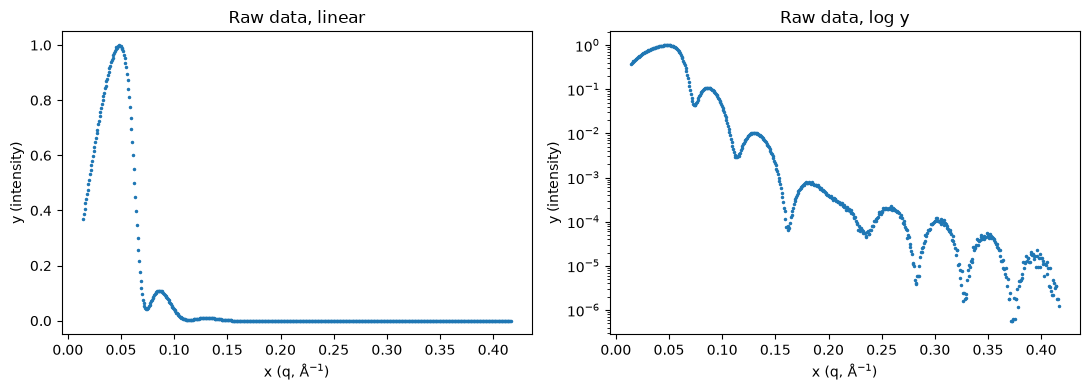

In [9]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4))

ax1.plot(df["x"], df["y"], ".", ms=3)
ax1.set(xlabel="x (q, Å$^{-1}$)", ylabel="y (intensity)", title="Raw data, linear")

ax2.semilogy(df["x"], df["y"], ".", ms=3)
ax2.set(xlabel="x (q, Å$^{-1}$)", ylabel="y (intensity)", title="Raw data, log y")

plt.tight_layout()
plt.show()

**Step 3:** operations on the axes.

- x: convert q (Å⁻¹) to 2θ (degrees) using q = 4π sinθ / λ
- y: take log10 of the reflectivity so the Kiessig fringes are easy to see

Assumes x is q in Å⁻¹ and Cu Kα radiation. Change `wavelength` if your source differs.

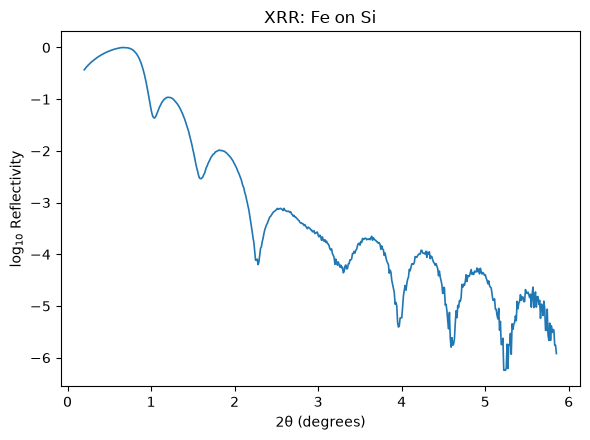

,x,two_theta,y,log_R
0,0.014242,0.200078,0.369966,-0.431838
1,0.014954,0.210082,0.388488,-0.410622
2,0.015666,0.220086,0.406306,-0.391147
3,0.016378,0.230090,0.425887,-0.370706
4,0.017090,0.240094,0.440689,-0.355868


In [10]:
wavelength = 1.5406                     # Å, Cu K-alpha

q = df["x"].to_numpy()
theta = np.arcsin(q * wavelength / (4 * np.pi))   # radians
df["two_theta"] = np.degrees(2 * theta)           # degrees
df["log_R"] = np.log10(df["y"])

fig, ax = plt.subplots(figsize=(6, 4.5))
ax.plot(df["two_theta"], df["log_R"], "-", lw=1.2)
ax.set(xlabel="2θ (degrees)", ylabel="log$_{10}$ Reflectivity",
       title="XRR: Fe on Si")
plt.tight_layout()
plt.show()

df[["x", "two_theta", "y", "log_R"]].head()

## Parratt fit
**Step 4:** the model. Parratt recursion for vacuum / (optional oxide cap) / Fe film / Si substrate, with Névot–Croce roughness. Nothing to edit in this cell.

In [17]:
from scipy.optimize import least_squares, differential_evolution

wavelength = 1.5406                 # Å (Cu K-alpha)
k0 = 2 * np.pi / wavelength

# Bulk optical constants at Cu K-alpha: refractive index n = 1 - delta + i*beta
DELTA_FE, BETA_FE = 2.24e-5, 2.9e-6
DELTA_SI, BETA_SI = 7.6e-6, 1.75e-7
CAP_REL = 0.6                       # oxide cap density relative to Fe (rough guess); scaled by dens_cap

def parratt(q, layers, sigma_sub, substrate=(DELTA_SI, BETA_SI)):
    """layers: list of (delta, beta, thickness_A, roughness_of_top_interface_A), top to bottom."""
    kz = q / 2
    media = [(0.0, 0.0)] + [(l[0], l[1]) for l in layers] + [substrate]
    kzs = [np.sqrt(kz**2 - 2 * k0**2 * (d - 1j * b) + 0j) for d, b in media]
    sig = [l[3] for l in layers] + [sigma_sub]
    thick = [l[2] for l in layers]
    n = len(media)
    r_tot = None
    for j in range(n - 2, -1, -1):
        r = (kzs[j] - kzs[j+1]) / (kzs[j] + kzs[j+1]) * np.exp(-2 * kzs[j] * kzs[j+1] * sig[j]**2)
        if r_tot is None:
            r_tot = r
        else:
            ph = np.exp(2j * kzs[j+1] * thick[j])
            r_tot = (r + r_tot * ph) / (1 + r * r_tot * ph)
    return np.abs(r_tot)**2

def xrr_model(p, q):
    layers = []
    if p["use_cap"] > 0.5:
        layers.append((DELTA_FE * CAP_REL * p["dens_cap"], BETA_FE * CAP_REL * p["dens_cap"],
                       p["t_cap"], p["sigma_cap"]))
    layers.append((DELTA_FE * p["dens_Fe"], BETA_FE * p["dens_Fe"], p["t_Fe"], p["sigma_Fe"]))
    return p["scale"] * parratt(q, layers, p["sigma_Si"]) + p["bg"]

**Step 5: fit settings. Edit this cell to change the fit.**

Each parameter is `[start value, min, max, vary]`. Set `vary` to `False` to hold a parameter fixed at its start value. Set `"use_cap"` to `0` for a single Fe layer, or `1` to include an oxide cap.

In [18]:
# name:        [start,  min,   max,  vary]
params = {
    "t_Fe":      [122.0,  60.0, 220.0, True],    # Fe thickness (Å)
    "sigma_Fe":  [  5.0,   0.0,  15.0, True],    # roughness of the top Fe (or cap) interface (Å)
    "sigma_Si":  [  3.0,   0.0,  15.0, True],    # Fe/Si interface roughness (Å)
    "dens_Fe":   [  1.0,   0.7,   1.2, True],    # Fe density relative to bulk
    "scale":     [  1.0,   0.5,   2.0, True],    # intensity scale factor
    "bg":        [  0.0,   0.0,  1e-6, False],   # constant background
    "use_cap":   [  1,     0,      1,  False],   # 1 = include oxide cap, 0 = no cap
    "t_cap":     [ 14.0,   0.0,  60.0, True],    # cap thickness (Å)
    "dens_cap":  [  0.8,   0.4,   1.5, True],    # cap density (relative to CAP_REL * Fe)
    "sigma_cap": [  3.0,   0.0,  10.0, True],    # roughness of the cap/Fe interface (Å)
}

q_min, q_max = 0.0, 0.42        # q-range used in the fit (Å^-1)
global_search = False           # True = slower global search first (more robust), then local refinement

**Step 6:** run the fit, print the results, and plot the data against the fit with residuals.

rms of log10(R) residuals: 0.265

t_Fe       =      121.6 ± 0.333      
sigma_Fe   =      5.945 ± 0.416      
sigma_Si   =       3.25 ± 0.0786     
dens_Fe    =        1.2 ± 0.022        <-- at a bound
scale      =          2 ± 0.114        <-- at a bound
bg         =          0              (fixed)
use_cap    =          1              (fixed)
t_cap      =      14.04 ± 0.229      
dens_cap   =     0.7758 ± 0.0868     
sigma_cap  =      2.769 ± 0.426      

Fe thickness  = 12.16 nm
Total (Fe + cap) = 13.57 nm


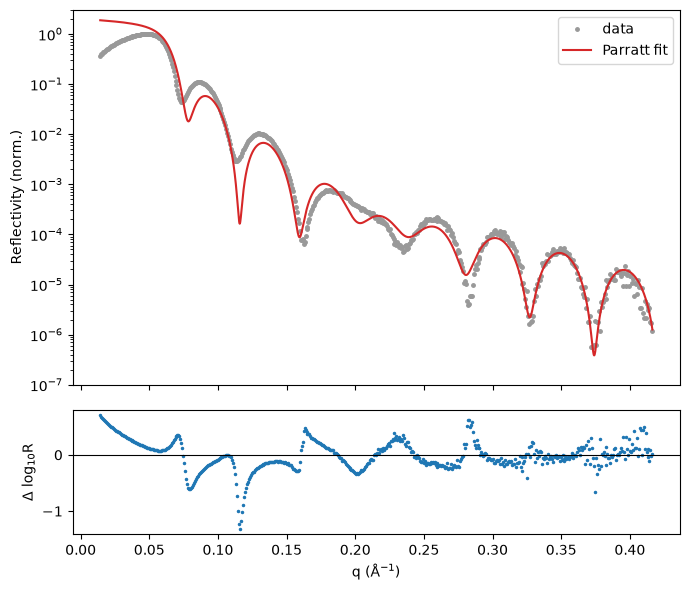

In [19]:
q_all, R_all = df["x"].to_numpy(), df["y"].to_numpy()
mask = (q_all >= q_min) & (q_all <= q_max)
q_fit, R_fit = q_all[mask], R_all[mask]

names = list(params)
free = [n for n in names if params[n][3] and not (n in ("use_cap",))]
if params["use_cap"][0] < 0.5:                 # no cap: do not fit cap parameters
    free = [n for n in free if n not in ("t_cap", "dens_cap", "sigma_cap")]

def pack(vec):
    p = {n: params[n][0] for n in names}
    p.update(dict(zip(free, vec)))
    return p

def residuals(vec, q=q_fit, R=R_fit):
    m = np.maximum(xrr_model(pack(vec), q), 1e-12)
    return np.log10(m) - np.log10(R)

x0 = [params[n][0] for n in free]
lo = [params[n][1] for n in free]
hi = [params[n][2] for n in free]

if global_search:
    de = differential_evolution(lambda v: np.sum(residuals(v)**2), list(zip(lo, hi)),
                                seed=0, maxiter=300, popsize=20, polish=False)
    x0 = de.x

res = least_squares(residuals, x0, bounds=(lo, hi))
best = pack(res.x)

# parameter uncertainties (1 sigma, statistical only)
dof = max(len(q_fit) - len(free), 1)
cov = np.linalg.pinv(res.jac.T @ res.jac) * np.sum(res.fun**2) / dof
err = dict(zip(free, np.sqrt(np.diag(cov))))

print(f"rms of log10(R) residuals: {np.sqrt(np.mean(res.fun**2)):.3f}\n")
for n in names:
    flag = "" if n in free else "(fixed)"
    e = f"± {err[n]:.3g}" if n in err else ""
    hit = "  <-- at a bound" if n in free and (np.isclose(best[n], params[n][1]) or np.isclose(best[n], params[n][2])) else ""
    print(f"{n:10s} = {best[n]:10.4g} {e:12s} {flag}{hit}")

total = best["t_Fe"] + (best["t_cap"] if best["use_cap"] > 0.5 else 0)
print(f"\nFe thickness  = {best['t_Fe']/10:.2f} nm")
print(f"Total (Fe + cap) = {total/10:.2f} nm")

# plot: data vs fit, and residuals
q_plot = np.linspace(q_all.min(), q_all.max(), 2000)
fig, (ax, axr) = plt.subplots(2, 1, figsize=(7, 6), sharex=True,
                              gridspec_kw={"height_ratios": [3, 1]})
ax.semilogy(q_all, R_all, "o", ms=2.5, color="0.6", label="data")
ax.semilogy(q_plot, xrr_model(best, q_plot), "-", color="C3", lw=1.5, label="Parratt fit")
ax.set(ylabel="Reflectivity (norm.)", ylim=(1e-7, 3))
ax.legend()
axr.plot(q_fit, res.fun, ".", ms=3)
axr.axhline(0, color="k", lw=0.8)
axr.set(xlabel="q (Å$^{-1}$)", ylabel="Δ log$_{10}$R")
plt.tight_layout()
plt.show()